<a href="https://colab.research.google.com/github/qaiserfatmi/Dengue/blob/main/Workshop_Trainning_AKU_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title 1. Install required packages

!pip -q install requests tqdm rdkit scikit-learn seaborn matplotlib tensorflow

In [2]:
#@title 2. Import required libraries

from pathlib import Path
from warnings import filterwarnings
filterwarnings("ignore")
import math
import time
import requests
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

In [3]:
# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:


# RDKit / cheminformatics

from rdkit import Chem
from rdkit.Chem import MACCSkeys, Draw, rdFingerprintGenerator
from rdkit.Chem.Draw import IPythonConsole

In [5]:
# Machine learning

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [6]:
# Neural network

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [7]:
# Reproducibility

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
%matplotlib inline
print("All libraries imported successfully.")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

All libraries imported successfully.
NumPy: 2.1.3
Pandas: 2.2.3
TensorFlow: 2.21.0



---
# ChEMBL DATA RETRIEVAL
---





In [8]:
#@title 3. Test ChEMBL API connection

CHEMBL_BASE = "https://www.ebi.ac.uk/chembl/api/data"
def test_chembl_connection(timeout=30):
    url = f"{CHEMBL_BASE}/status.json"
    try:
        r = requests.get(url, timeout=timeout)
        print("Status code:", r.status_code)
        r.raise_for_status()
        print("ChEMBL API is reachable.")
        return True
    except Exception as e:
        print("ChEMBL API connection problem:")
        print(e)
        return False
chembl_ok = test_chembl_connection()

Status code: 200
ChEMBL API is reachable.


In [9]:
#@title 4. ChEMBL REST API helper functions

def chembl_get(endpoint, params=None, timeout=60):
    """
    Query ChEMBL REST API and return JSON.
    endpoint examples:
    - "target/search"
    - "activity"
    - "molecule"
    """
    url = f"{CHEMBL_BASE}/{endpoint}.json"
    try:
        r = requests.get(url, params=params, timeout=timeout)
        r.raise_for_status()
        return r.json()
    except requests.exceptions.HTTPError as e:
        print("HTTP error:", e)
        print("URL:", r.url)
        raise
    except requests.exceptions.RequestException as e:
        print("Request error:", e)
        raise
def chembl_get_all(endpoint, params=None, result_key=None, limit=1000, max_records=None):
    """
    Retrieve paginated ChEMBL records.
    Parameters
    ----------
    endpoint : str
        ChEMBL API endpoint, e.g., "activity"
    params : dict
        Query parameters
    result_key : str
        Key containing records in returned JSON, e.g., "activities", "targets"
    limit : int
        Number of records per page
    max_records : int or None
        Optional maximum number of records to retrieve
    """
    if params is None:
        params = {}
    all_records = []
    offset = 0
    while True:
        query_params = params.copy()
        query_params["limit"] = limit
        query_params["offset"] = offset
        data = chembl_get(endpoint, params=query_params)
        if result_key is None:
            possible_keys = [k for k in data.keys() if isinstance(data[k], list)]
            if len(possible_keys) == 0:
                raise ValueError("Could not automatically find result list in API response.")
            result_key = possible_keys[0]
        records = data.get(result_key, [])
        all_records.extend(records)
        print(f"Retrieved {len(all_records)} records...", end="\r")
        if len(records) < limit:
            break
        offset += limit
        if max_records is not None and len(all_records) >= max_records:
            all_records = all_records[:max_records]
            break
    print(f"\nTotal records retrieved: {len(all_records)}")
    return all_records

In [10]:
#@title 5. Search ChEMBL target
# Change this query according to your target.
# Examples:
# target_query = "Plasmodium falciparum"
# target_query = "dengue NS3 protease"
# target_query = "dengue NS5 polymerase"
# target_query = "CHEMBL5980"
target_query = "dengue NS3 protease"
target_data = chembl_get(
    "target/search",
    params={"q": target_query, "limit": 30}
)
targets = pd.DataFrame(target_data.get("targets", []))
if len(targets) == 0:
    print("No target found. Try a different target name or ChEMBL target ID.")
else:
    display_cols = ["target_chembl_id", "pref_name", "organism", "target_type"]
    display_cols = [c for c in display_cols if c in targets.columns]
    display(targets[display_cols])

,target_chembl_id,pref_name,organism,target_type
0,CHEMBL4296313,NS3 protease,Hepacivirus C,SINGLE PROTEIN
1,CHEMBL4296325,NS3 protease,Hepatitis C virus subtype 1b,SINGLE PROTEIN
2,CHEMBL5705862,NS3 protease,dengue virus type 1,SINGLE PROTEIN
3,CHEMBL5705864,NS3 protease,dengue virus type 4,SINGLE PROTEIN
4,CHEMBL5705863,NS3 protease,dengue virus type 3,SINGLE PROTEIN
5,CHEMBL5981,Genome polyprotein,GB virus-B,SINGLE PROTEIN
6,CHEMBL5536,Genome polyprotein,Hepatitis C virus genotype 1b (isolate Con1) (...,SINGLE PROTEIN
7,CHEMBL6040,Genome polyprotein,Hepatitis C virus genotype 1b (isolate BK) (HCV),SINGLE PROTEIN
8,CHEMBL4620,Genome polyprotein,Hepatitis C virus genotype 1a (isolate 1) (HCV),SINGLE PROTEIN
9,CHEMBL3638332,Genome polyprotein,Hepatitis C virus genotype 1b (strain HC-J4) (...,SINGLE PROTEIN


In [12]:
#@title 6. Select target
# Option A: Select the first target from the search result
selected_target = targets.loc[17, "target_chembl_id"]
#selected_target = targets.loc[[2, 3, 4], "target_chembl_id"].tolist()
# Option B: Manually set a ChEMBL target ID
# selected_target = "CHEMBL5705862"
print("Selected target:", selected_target)

Selected target: CHEMBL5980


In [13]:
#@title 7. Retrieve IC50 bioactivity data from ChEMBL

activity_params = {
    "target_chembl_id": selected_target,
    "standard_type": "IC50",
    "standard_units": "nM"
}
activity_records = chembl_get_all(
    endpoint="activity",
    params=activity_params,
    result_key="activities",
    limit=1000
)
df_raw = pd.DataFrame(activity_records)
print("Raw activity data shape:", df_raw.shape)
df_raw.head()

Retrieved 6287 records...
Total records retrieved: 6287
Raw activity data shape: (6287, 47)


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,active,7018430,[],CHEMBL1794550,PUBCHEM_BIOASSAY: Primary and Confirmatory Scr...,F,None,None,BAO_0000190,...,dengue virus type 2,Genome polyprotein,11060,None,None,IC50,uM,UO_0000065,None,100.0
1,None,active,7018431,[],CHEMBL1794550,PUBCHEM_BIOASSAY: Primary and Confirmatory Scr...,F,None,None,BAO_0000190,...,dengue virus type 2,Genome polyprotein,11060,None,None,IC50,uM,UO_0000065,None,12.31
2,None,active,7018432,[],CHEMBL1794550,PUBCHEM_BIOASSAY: Primary and Confirmatory Scr...,F,None,None,BAO_0000190,...,dengue virus type 2,Genome polyprotein,11060,None,None,IC50,uM,UO_0000065,None,100.0
3,None,active,7018433,[],CHEMBL1794550,PUBCHEM_BIOASSAY: Primary and Confirmatory Scr...,F,None,None,BAO_0000190,...,dengue virus type 2,Genome polyprotein,11060,None,None,IC50,uM,UO_0000065,None,50.97
4,None,active,7018434,[],CHEMBL1794550,PUBCHEM_BIOASSAY: Primary and Confirmatory Scr...,F,None,None,BAO_0000190,...,dengue virus type 2,Genome polyprotein,11060,None,None,IC50,uM,UO_0000065,None,100.0


In [14]:
#@title 8. Save raw ChEMBL data

df_raw.to_csv("01_data_1_raw_chembl.csv", index=False)
print("Saved raw data as data_1_raw_chembl.csv")

Saved raw data as data_1_raw_chembl.csv




---
DATA CLEANING AND pIC50 CALCULATION
---




In [15]:
#@title 9. Clean bioactivity data

required_cols = [
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_value",
    "standard_units",
    "standard_type",
    "target_chembl_id",
    "assay_chembl_id"
]
available_cols = [c for c in required_cols if c in df_raw.columns]
df_clean = df_raw[available_cols].copy()
# Remove missing SMILES and IC50 values
df_clean = df_clean.dropna(subset=["canonical_smiles", "standard_value"])
# Convert IC50 to numeric
df_clean["standard_value"] = pd.to_numeric(df_clean["standard_value"], errors="coerce")
df_clean = df_clean.dropna(subset=["standard_value"])
# Keep only positive IC50 values
df_clean = df_clean[df_clean["standard_value"] > 0]
# Keep only nM values if unit column exists
if "standard_units" in df_clean.columns:
    df_clean = df_clean[df_clean["standard_units"] == "nM"]
# Remove duplicate compounds based on canonical SMILES
df_clean = df_clean.drop_duplicates(subset=["canonical_smiles"]).reset_index(drop=True)
print("Cleaned data shape:", df_clean.shape)
df_clean.head()

Cleaned data shape: (3971, 7)


,molecule_chembl_id,canonical_smiles,standard_value,standard_units,standard_type,target_chembl_id,assay_chembl_id
0,CHEMBL1401841,COc1ccc2nc3cccc(OC)c3nc2c1,100000.0,nM,IC50,CHEMBL5980,CHEMBL1794550
1,CHEMBL1608853,O=C(O)c1ccc2c(c1)C(=O)/C(=C\c1ccco1)C2=O,12310.0,nM,IC50,CHEMBL5980,CHEMBL1794550
2,CHEMBL1429799,O=C1NN(c2ccccc2)C(=O)/C1=C\c1ccccc1OCC(=O)N1CC...,100000.0,nM,IC50,CHEMBL5980,CHEMBL1794550
3,CHEMBL246446,O=C(O)c1ccc2nc(-c3ccco3)c(-c3ccco3)nc2c1,50970.0,nM,IC50,CHEMBL5980,CHEMBL1794550
4,CHEMBL1383455,CCn1nc([N+](=O)[O-])c(C(C#N)c2nc3ccccc3n2C)c(C...,100000.0,nM,IC50,CHEMBL5980,CHEMBL1794550


In [16]:
#@title 10. Assign bioactivity classes

def assign_bioactivity_class(ic50_nM):
    """
    Assign bioactivity class based on IC50 in nM.
    active: IC50 <= 20,000 nM
    inactive: IC50 >= 50,000 nM
    intermediate: between 20,000 and 50,000 nM
    """
    if ic50_nM <= 20000:
        return "active"
    elif ic50_nM >= 50000:
        return "inactive"
    else:
        return "intermediate"
df_clean["class"] = df_clean["standard_value"].apply(assign_bioactivity_class)
df_clean["class"].value_counts()

,count
class,
inactive,2902
intermediate,587
active,482


In [17]:
#@title 11. Calculate pIC50

def calculate_pic50(df, value_col="standard_value"):
    """
    Convert IC50 in nM to pIC50.
    pIC50 = -log10(IC50 in molar)
    Since standard_value is in nM:
    IC50(M) = IC50(nM) x 10^-9
    """
    df = df.copy()
    # Cap extremely large IC50 values to avoid unrealistic pIC50 values
    df[value_col] = df[value_col].clip(upper=100000000)
    # Convert nM to M and calculate pIC50
    df["pIC50"] = -np.log10(df[value_col] * 1e-9)
    return df
df_final = calculate_pic50(df_clean)
print(df_final[["canonical_smiles", "standard_value", "pIC50", "class"]].head())
print("\npIC50 summary:")
print(df_final["pIC50"].describe())

                                    canonical_smiles  standard_value  \
0                         COc1ccc2nc3cccc(OC)c3nc2c1        100000.0   
1           O=C(O)c1ccc2c(c1)C(=O)/C(=C\c1ccco1)C2=O         12310.0   
2  O=C1NN(c2ccccc2)C(=O)/C1=C\c1ccccc1OCC(=O)N1CC...        100000.0   
3           O=C(O)c1ccc2nc(-c3ccco3)c(-c3ccco3)nc2c1         50970.0   
4  CCn1nc([N+](=O)[O-])c(C(C#N)c2nc3ccccc3n2C)c(C...        100000.0   

      pIC50     class  
0  4.000000  inactive  
1  4.909742    active  
2  4.000000  inactive  
3  4.292685  inactive  
4  4.000000  inactive  

pIC50 summary:
count    3971.000000
mean        4.227561
std         0.418175
min         3.364516
25%         4.000000
50%         4.002177
75%         4.346981
max         8.221849
Name: pIC50, dtype: float64


In [18]:
#@title 12. Validate final data
print("Total rows:", len(df_final))
print("Missing pIC50:", df_final["pIC50"].isna().sum())
print("Infinite pIC50:", np.isinf(df_final["pIC50"]).sum())
print("Missing SMILES:", df_final["canonical_smiles"].isna().sum())

# Remove invalid pIC50 values if any
df_final = df_final.replace([np.inf, -np.inf], np.nan)
df_final = df_final.dropna(subset=["canonical_smiles", "pIC50"])
df_final = df_final.reset_index(drop=True)
print("Final clean data shape:", df_final.shape)

Total rows: 3971
Missing pIC50: 0
Infinite pIC50: 0
Missing SMILES: 0
Final clean data shape: (3971, 9)


In [19]:
#@title 13. Save final cleaned dataset

df_final.to_csv("02_Data_Final.csv", index=False)
print("Saved final cleaned dataset as Data_Final.csv")

Saved final cleaned dataset as Data_Final.csv




---
VISUALIZATION
---




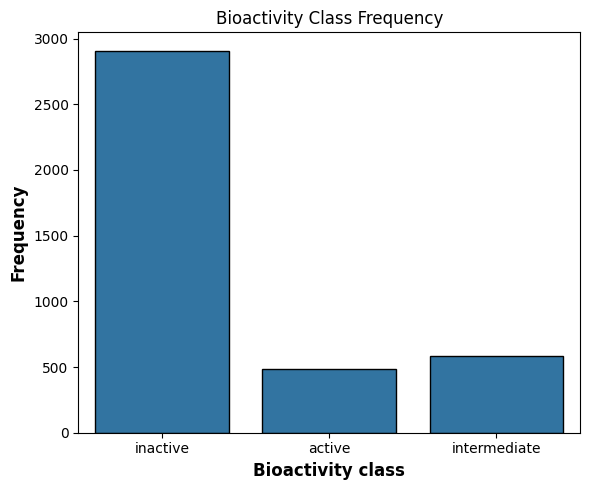

In [20]:
#@title 14. Bioactivity class frequency plot

plt.figure(figsize=(6, 5))
sns.countplot(x="class", data=df_final, edgecolor="black")
plt.xlabel("Bioactivity class", fontsize=12, fontweight="bold")
plt.ylabel("Frequency", fontsize=12, fontweight="bold")
plt.title("Bioactivity Class Frequency")
plt.tight_layout()
plt.savefig("bioactivity_class_frequency.png", dpi=300)
plt.show()

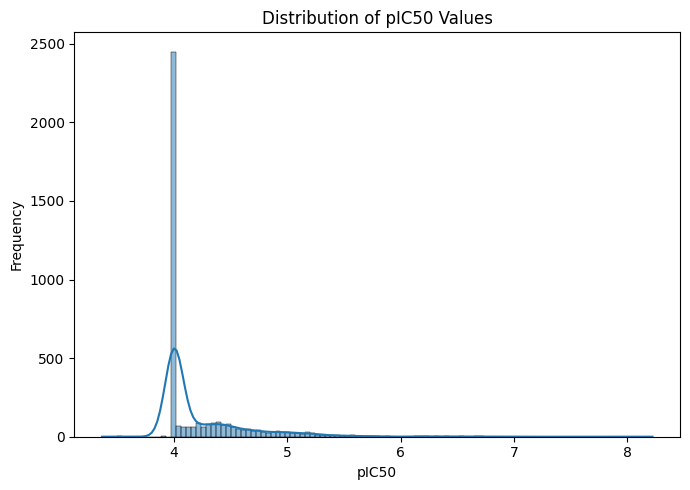

In [21]:
#@title 15. pIC50 distribution plot

plt.figure(figsize=(7, 5))
sns.histplot(df_final["pIC50"], kde=True)
plt.title("Distribution of pIC50 Values")
plt.xlabel("pIC50")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("pIC50_distribution.png", dpi=300)
plt.show()

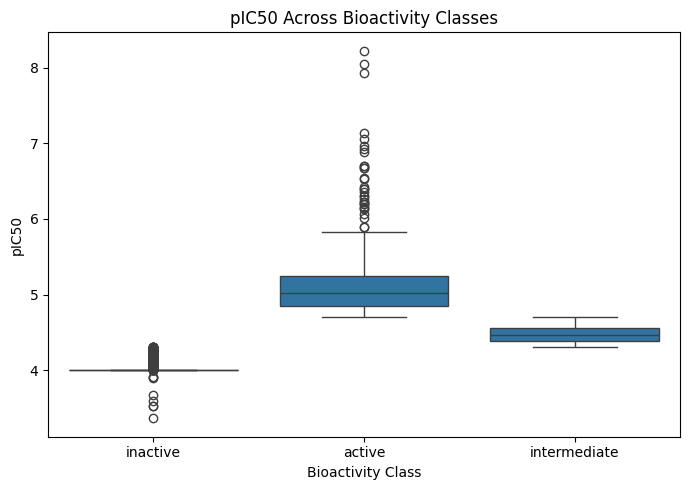

In [22]:
#@title 16. pIC50 vs bioactivity class

plt.figure(figsize=(7, 5))
sns.boxplot(data=df_final, x="class", y="pIC50")
plt.title("pIC50 Across Bioactivity Classes")
plt.xlabel("Bioactivity Class")
plt.ylabel("pIC50")
plt.tight_layout()
plt.savefig("pIC50_bioactivity_classes.png", dpi=300)
plt.show()



---
FINGERPRINT GENERATION
---




In [23]:
#@title 17. Prepare dataset for machine learning

# For neural network regression, we only need:
# canonical_smiles = input structure
# pIC50 = numerical output
chembl_df = df_final[["canonical_smiles", "pIC50"]].copy()
print("ML dataset shape:", chembl_df.shape)
chembl_df.head()
#@title 18. Convert SMILES to molecular fingerprints
def smiles_to_fp(smiles, method="maccs", n_bits=2048):
    """
    Convert a SMILES string into a molecular fingerprint.
    method options:
    - "maccs"
    - "morgan2"
    - "morgan3"
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    if method == "maccs":
        return np.array(MACCSkeys.GenMACCSKeys(mol), dtype=float)
    elif method == "morgan2":
        fpg = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=n_bits)
        return np.array(fpg.GetFingerprint(mol), dtype=float)
    elif method == "morgan3":
        fpg = rdFingerprintGenerator.GetMorganGenerator(radius=3, fpSize=n_bits)
        return np.array(fpg.GetFingerprint(mol), dtype=float)
    else:
        print(f"Unknown method '{method}'. Using MACCS keys instead.")
        return np.array(MACCSkeys.GenMACCSKeys(mol), dtype=float)
# Select fingerprint type
fingerprint_method = "maccs"
chembl_df["fingerprint"] = chembl_df["canonical_smiles"].apply(
    lambda x: smiles_to_fp(x, method=fingerprint_method)
)
# Remove invalid SMILES
chembl_df = chembl_df[chembl_df["fingerprint"].notna()].reset_index(drop=True)
print("Dataset after fingerprint generation:", chembl_df.shape)
chembl_df.head()
#@title 19. Create X and y arrays
X = np.stack(chembl_df["fingerprint"].values)
y = chembl_df["pIC50"].values.astype(float)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("pIC50 min:", y.min())
print("pIC50 max:", y.max())


ML dataset shape: (3971, 2)
Dataset after fingerprint generation: (3971, 3)
X shape: (3971, 167)
y shape: (3971,)
pIC50 min: 3.364516253185088
pIC50 max: 8.221848749616356


In [24]:
#@title 20. Train-test split

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)
print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

x_train shape: (3176, 167)
x_test shape: (795, 167)
y_train shape: (3176,)
y_test shape: (795,)




---
NEURAL NETWORK MODEL
---




In [25]:
#@title 21. Define neural network model

def neural_network_model(input_dim, hidden1=64, hidden2=32, dropout_rate=0.0):
    """
    Fully connected neural network for pIC50 regression.
    """
    model = Sequential()
    model.add(Dense(hidden1, activation="relu", input_shape=(input_dim,), name="hidden_layer_1"))
    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))
    model.add(Dense(hidden2, activation="relu", name="hidden_layer_2"))
    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))
    model.add(Dense(1, activation="linear", name="output_layer"))
    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
        metrics=["mse", "mae"]
    )
    return model

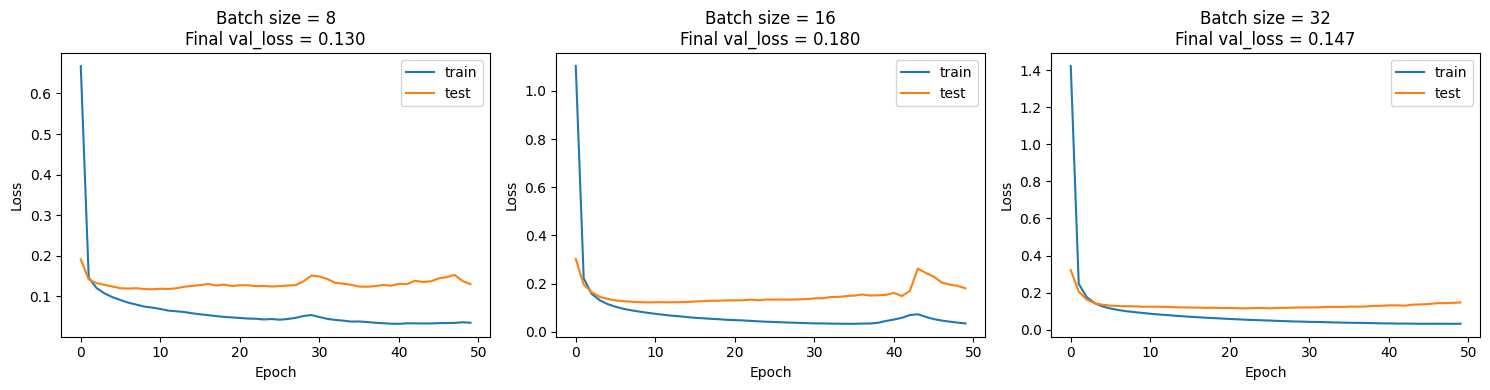

In [26]:
#@title 22. Test different batch sizes

batch_sizes = [8, 16, 32]
num_epochs = 50
layer1_size = 64
layer2_size = 32
plt.figure(figsize=(15, 4))
history_dict = {}
for index, batch in enumerate(batch_sizes):
    plt.subplot(1, len(batch_sizes), index + 1)
    model_temp = neural_network_model(
        input_dim=x_train.shape[1],
        hidden1=layer1_size,
        hidden2=layer2_size
    )
    history = model_temp.fit(
        x_train,
        y_train,
        validation_data=(x_test, y_test),
        batch_size=batch,
        epochs=num_epochs,
        verbose=0
    )
    history_dict[batch] = history
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="test")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Batch size = {batch}\nFinal val_loss = {history.history['val_loss'][-1]:.3f}")
    plt.legend()
plt.tight_layout()
plt.savefig("batch_size_loss_comparison.png", dpi=300)
plt.show()

In [27]:
final_batch_size = 8
num_epochs = 100
model = neural_network_model(
    input_dim=x_train.shape[1],
    hidden1=64,
    hidden2=32
)
checkpoint = ModelCheckpoint(
    filepath="best_weights.weights.h5",
    monitor="val_loss",
    verbose=1,
    save_best_only=True,
    mode="min",
    save_weights_only=True
)
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=num_epochs,
    batch_size=final_batch_size,
    callbacks=[checkpoint, early_stop],
    verbose=1
)

Epoch 1/100
396/397 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.4120 - mae: 1.0412 - mse: 2.4120
Epoch 1: val_loss improved from None to 0.20436, saving model to best_weights.weights.h5

Epoch 1: finished saving model to best_weights.weights.h5
397/397 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.8076 - mae: 0.5654 - mse: 0.8076 - val_loss: 0.2044 - val_mae: 0.3154 - val_mse: 0.2044
Epoch 2/100
386/397 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1594 - mae: 0.2826 - mse: 0.1594
Epoch 2: val_loss improved from 0.20436 to 0.15464, saving model to best_weights.weights.h5

Epoch 2: finished saving model to best_weights.weights.h5
397/397 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1513 - mae: 0.2748 - mse: 0.1513 - val_loss: 0.1546 - val_mae: 0.2679 - val_mse: 0.1546
Epoch 3/100
378/397 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1240 - mae: 0.2463 - mse: 0.1240
Epoch 3: val_loss improved from 0.15464 to 0.13630, saving model to best_weights.weights.h5

Epoch 3: finished saving model to best_wei

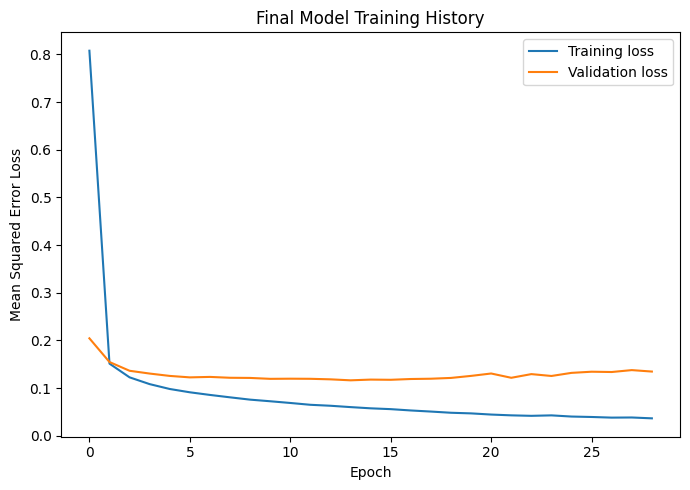

In [28]:
#@title 24. Plot final training history

plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.title("Final Model Training History")
plt.legend()
plt.tight_layout()
plt.savefig("final_model_training_history.png", dpi=300)
plt.show()



---
MODEL EVALUATION
---




In [29]:
#@title 25. Evaluate model on test data

scores = model.evaluate(x_test, y_test, verbose=0)
print("Model evaluation on test set")
print(f"Loss/MSE: {scores[0]:.3f}")
print(f"MSE     : {scores[1]:.3f}")
print(f"MAE     : {scores[2]:.3f}")

Model evaluation on test set
Loss/MSE: 0.116
MSE     : 0.116
MAE     : 0.233


In [30]:
#@title 26. Predict pIC50 values for test set

y_pred = model.predict(x_test).flatten()
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Regression metrics")
print(f"RMSE: {rmse:.3f}")
print(f"MAE : {mae:.3f}")
print(f"R²  : {r2:.3f}")
print("\nFirst 5 predictions:")
for i in range(min(5, len(y_pred))):
    print(f"Experimental pIC50: {y_test[i]:.2f} | Predicted pIC50: {y_pred[i]:.2f}")

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Regression metrics
RMSE: 0.341
MAE : 0.233
R²  : 0.368

First 5 predictions:
Experimental pIC50: 4.00 | Predicted pIC50: 3.93
Experimental pIC50: 4.00 | Predicted pIC50: 4.12
Experimental pIC50: 4.00 | Predicted pIC50: 4.10
Experimental pIC50: 4.00 | Predicted pIC50: 4.18
Experimental pIC50: 4.00 | Predicted pIC50: 4.10


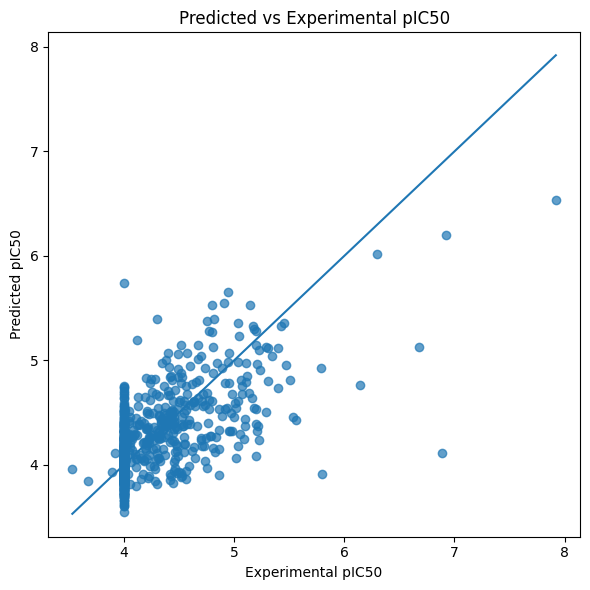

In [31]:
#@title 27. Predicted vs experimental pIC50 plot

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val])
plt.xlabel("Experimental pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Predicted vs Experimental pIC50")
plt.tight_layout()
plt.savefig("predicted_vs_experimental_pIC50.png", dpi=300)
plt.show()



---
SAVE MODEL
---




In [33]:
#@title 28. Save final trained model
model.save("pIC50_prediction_model.keras")
print("Saved model as pIC50_prediction_model.keras")

# Optional: save architecture and weights separately
model_json = model.to_json()
with open("model.json", "w") as json_file:
    json_file.write(model_json)
model.save_weights("model.weights.h5")
print("Saved model.json and model.weights.h5")

Saved model as pIC50_prediction_model.keras
Saved model.json and model.weights.h5




---
PREDICT UNKNOWN COMPOUNDS
---




In [35]:
#@title 29. Upload or load unknown compound dataset

# Your unknown dataset must contain at least one column:
# canonical_smiles
# Example path:
unknown_file = "/content/unk.csv"
external_data = pd.read_csv(unknown_file)
external_data = external_data.reset_index(drop=True)
print("External data shape:", external_data.shape)
external_data.head()

External data shape: (8, 2)


,compound_name,canonical_smiles
0,Chloroquine,CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl
1,Aspirin,CC(=O)OC1=CC=CC=C1C(=O)O
2,Metformin,CN(C)C(=N)N=C(N)N
3,Nicotine,CN1CCC[C@H]1C2=CN=CC=C2
4,Bisacodyl,CC(=O)OC1=CC=C(C=C1)C(C2=CC=C(C=C2)OC(=O)C)C3=...


In [36]:
#@title 30. Validate unknown dataset
if "canonical_smiles" not in external_data.columns:
    raise ValueError("The unknown dataset must contain a column named 'canonical_smiles'.")
external_data = external_data.dropna(subset=["canonical_smiles"]).reset_index(drop=True)
print("External data after removing missing SMILES:", external_data.shape)

External data after removing missing SMILES: (8, 2)


In [37]:
#@title 31. Generate fingerprints for unknown compounds

external_data["fingerprint"] = external_data["canonical_smiles"].apply(
    lambda x: smiles_to_fp(x, method=fingerprint_method)
)
external_data = external_data[external_data["fingerprint"].notna()].reset_index(drop=True)
X_external = np.stack(external_data["fingerprint"].values)
print("External fingerprint matrix shape:", X_external.shape)

External fingerprint matrix shape: (8, 167)


In [38]:
#@title 32. Predict pIC50 for unknown compounds

predictions = model.predict(X_external).flatten()
external_data["predicted_pIC50"] = predictions
external_data.head()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


,compound_name,canonical_smiles,fingerprint,predicted_pIC50
0,Chloroquine,CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3.924961
1,Aspirin,CC(=O)OC1=CC=CC=C1C(=O)O,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",4.593351
2,Metformin,CN(C)C(=N)N=C(N)N,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",2.666466
3,Nicotine,CN1CCC[C@H]1C2=CN=CC=C2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",4.098645
4,Bisacodyl,CC(=O)OC1=CC=C(C=C1)C(C2=CC=C(C=C2)OC(=O)C)C3=...,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",4.176460


In [41]:
#@title 33. Save predictions

external_data.to_csv("predictions.csv", index=False)
print("Saved predictions as predictions.csv")

Saved predictions as predictions.csv


In [42]:
#@title 34. Rank unknown compounds by predicted pIC50

ranked_predictions = external_data.sort_values(
    by="predicted_pIC50",
    ascending=False
).reset_index(drop=True)
ranked_predictions.to_csv("predictions_ranked.csv", index=False)
ranked_predictions.head(10)

,compound_name,canonical_smiles,fingerprint,predicted_pIC50
0,Atorvastatin Calcium,CC(C)C1=C(C(=C(N1CC[C@H](C[C@H](CC(=O)[O-])O)O...,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",4.979402
1,Aspirin,CC(=O)OC1=CC=CC=C1C(=O)O,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",4.593351
2,Bisacodyl,CC(=O)OC1=CC=C(C=C1)C(C2=CC=C(C=C2)OC(=O)C)C3=...,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",4.176460
3,Nicotine,CN1CCC[C@H]1C2=CN=CC=C2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",4.098645
4,Chloroquine,CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3.924961
5,Buprenorphine,C[C@]([C@H]1C[C@@]23CC[C@@]1([C@H]4[C@@]25CCN(...,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3.894138
6,5-Tert-butoxyquinazoline-2-4-diamine,CC(C)(C)OC1=CC=CC2=C1C(=NC(=N2)N)N,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3.719667
7,Metformin,CN(C)C(=N)N=C(N)N,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",2.666466
